# Treinando uma rede neural quântica

Imports:

In [42]:
# pip install qiskit qiskit-machine-learning torch matplotlib scikit-learn

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import TensorDataset, DataLoader

from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes
from qiskit.quantum_info import SparsePauliOp
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.connectors import TorchConnector

Criando dataset onde é da classe 1 se estiver dentro do círculo:

In [43]:
np.random.seed(42)
torch.manual_seed(42)

# A QNN simulada fica cara rapidamente. 600 pontos é um bom compromisso
# entre estabilidade estatística e tempo de treino em CPU/GPU comum.
N = 600
X = np.random.uniform(-1, 1, size=(N, 2))

# classe 1 se estiver dentro do círculo
radius_squared = 0.5
y = ((X[:, 0] ** 2 + X[:, 1] ** 2) < radius_squared).astype(np.float32)

# Expandimos as features para usar 4 qubits. As duas primeiras features são
# as coordenadas originais; as duas últimas ajudam a representar a fronteira circular.
X_features = np.column_stack([
    X[:, 0],
    X[:, 1],
    X[:, 0] ** 2,
    X[:, 1] ** 2,
])

# Qiskit trabalha melhor com ângulos, então escalamos para [0, pi]
scaler = MinMaxScaler(feature_range=(0, np.pi))
#X_scaled = scaler.fit_transform(X_features)
X_scaled = scaler.fit_transform(X)

X_train_np, X_test_np, y_train_np, y_test_np = train_test_split(
    X_scaled, y, test_size=0.25, random_state=42, stratify=y
)

X_train = torch.tensor(X_train_np, dtype=torch.float32)
y_train = torch.tensor(y_train_np, dtype=torch.float32).reshape(-1, 1)

X_test = torch.tensor(X_test_np, dtype=torch.float32)
y_test = torch.tensor(y_test_np, dtype=torch.float32).reshape(-1, 1)

batch_size = 32
train_loader = DataLoader(
    TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando device: {device}")
print(f"Amostras de treino: {len(X_train)} | teste: {len(X_test)}")
print(f"Proporção da classe 1 no treino: {y_train.mean().item():.4f}")
print(f"Proporção da classe 1 no teste: {y_test.mean().item():.4f}")
print(f"Baseline classe majoritária no teste: {max(y_test.mean().item(), 1 - y_test.mean().item()):.4f}")

Usando device: cpu
Amostras de treino: 450 | teste: 150
Proporção da classe 1 no treino: 0.3578
Proporção da classe 1 no teste: 0.3600
Baseline classe majoritária no teste: 0.6400


Visualizando os dados antes e depois da escala para `[0, pi]`:

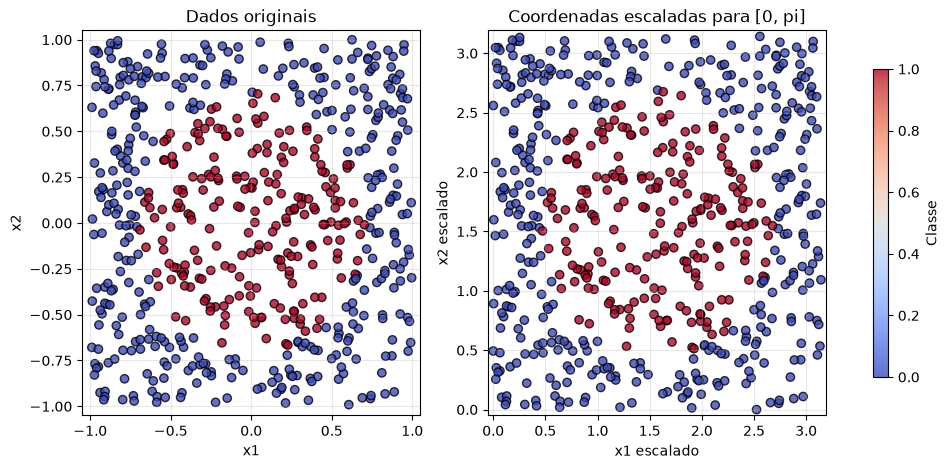

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

scatter_original = axes[0].scatter(
    X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", alpha=0.8
)
axes[0].set_title("Dados originais")
axes[0].set_xlabel("x1")
axes[0].set_ylabel("x2")
axes[0].set_xlim(-1.05, 1.05)
axes[0].set_ylim(-1.05, 1.05)
axes[0].grid(alpha=0.3)

scatter_scaled = axes[1].scatter(
    X_scaled[:, 0], X_scaled[:, 1], c=y, cmap="coolwarm", edgecolor="k", alpha=0.8
)
axes[1].set_title("Coordenadas escaladas para [0, pi]")
axes[1].set_xlabel("x1 escalado")
axes[1].set_ylabel("x2 escalado")
axes[1].set_xlim(-0.05, np.pi + 0.05)
axes[1].set_ylim(-0.05, np.pi + 0.05)
axes[1].grid(alpha=0.3)

fig.colorbar(scatter_scaled, ax=axes, label="Classe", shrink=0.8)
plt.show()

Criando circuito quântico:

In [45]:
num_qubits = X_train.shape[1]

feature_map = ZZFeatureMap(feature_dimension=num_qubits, reps=2)
ansatz = RealAmplitudes(num_qubits=num_qubits, reps=3, entanglement="full")

qc = feature_map.compose(ansatz)

# Mede Z individualmente em cada qubit → saída (batch, num_qubits)
observables = []
for i in range(num_qubits):
    label = ['I'] * num_qubits
    label[i] = 'Z'
    observables.append(SparsePauliOp(''.join(reversed(label))))

qnn = EstimatorQNN(
    circuit=qc,
    input_params=feature_map.parameters,
    weight_params=ansatz.parameters,
    observables=observables,
)

quantum_layer = TorchConnector(qnn)
print(f"Número de qubits: {num_qubits}")
print(f"Parâmetros treináveis da QNN: {len(ansatz.parameters)}")
print(f"Observáveis: medir Z em cada qubit → saída {num_qubits}-dimensional")

/tmp/ipykernel_10472/1298617402.py:3: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(feature_dimension=num_qubits, reps=2)
/tmp/ipykernel_10472/1298617402.py:4: DeprecationWarning: The class ``qiskit.circuit.library.n_local.real_amplitudes.RealAmplitudes`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.real_amplitudes instead.
  ansatz = RealAmplitudes(num_qubits=num_qubits, reps=3, entanglement="full")
No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


Número de qubits: 2
Parâmetros treináveis da QNN: 8
Observáveis: medir Z em cada qubit → saída 2-dimensional


Visualizando o circuito quântico usado:

Feature map: codifica os dados clássicos no circuito


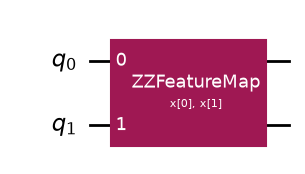

In [46]:
print("Feature map: codifica os dados clássicos no circuito")
feature_map.draw("mpl")

Circuito completo: feature map + ansatz treinável


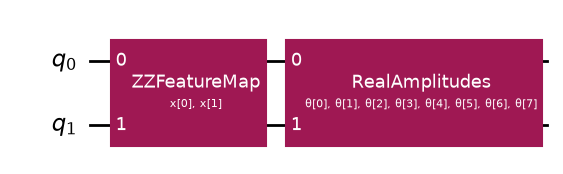

In [47]:
print("Circuito completo: feature map + ansatz treinável")
qc.draw("mpl")

In [48]:
class HybridQNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.qnn = quantum_layer
        self.classifier = nn.Sequential(
            nn.Linear(num_qubits, 4),
            nn.Tanh(),
            nn.Linear(4, 1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        x = self.qnn(x)          # saída em [-1, 1] para cada qubit
        x = self.classifier(x)   # converte a saída quântica em probabilidade
        return x

model = HybridQNN().to(device)

criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

Treinando modelo:

In [49]:
epochs = 300
patience = 20
best_test_acc = 0.0
epochs_without_improvement = 0
best_model_state = None

history = {
    "train_loss": [],
    "train_acc": [],
    "test_acc": [],
}

X_test_device = X_test.to(device)
y_test_device = y_test.to(device)

for epoch in range(epochs):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        batch_size_current = X_batch.shape[0]
        total_loss += loss.item() * batch_size_current
        total_correct += ((y_pred >= 0.5).float() == y_batch).sum().item()
        total_examples += batch_size_current

    train_loss = total_loss / total_examples
    train_acc = total_correct / total_examples

    model.eval()
    with torch.no_grad():
        y_pred_test = model(X_test_device)
        test_acc = ((y_pred_test >= 0.5).float() == y_test_device).float().mean().item()

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_acc"].append(test_acc)

    if test_acc > best_test_acc:
        best_test_acc = test_acc
        epochs_without_improvement = 0
        best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
    else:
        epochs_without_improvement += 1

    if epoch % 10 == 0 or epoch == epochs - 1:
        print(
            f"Epoch {epoch:03d} | Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}"
        )

    if epochs_without_improvement >= patience:
        print(f"Early stopping na época {epoch} (sem melhoria por {patience} épocas)")
        break

if best_model_state is not None:
    model.load_state_dict(best_model_state)
    print(f"Melhor acurácia de teste: {best_test_acc:.4f}")

Epoch 000 | Loss: 0.6595 | Train Acc: 0.6422 | Test Acc: 0.6400
Epoch 010 | Loss: 0.6501 | Train Acc: 0.6422 | Test Acc: 0.6400
Epoch 020 | Loss: 0.6437 | Train Acc: 0.6422 | Test Acc: 0.6400
Early stopping na época 20 (sem melhoria por 20 épocas)
Melhor acurácia de teste: 0.6400


Testando:


Acurácia final da QNN no teste: 0.6400


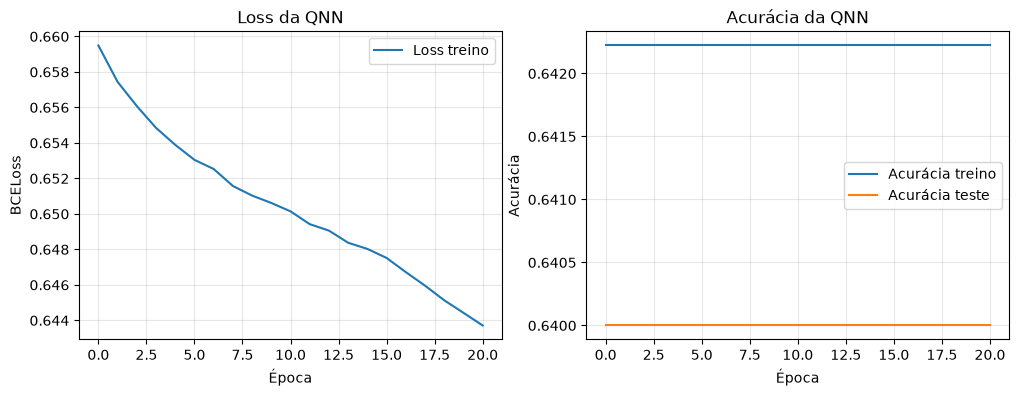

In [50]:
model.eval()

with torch.no_grad():
    y_pred_test = model(X_test.to(device))
    y_pred_class = (y_pred_test >= 0.5).float()
    test_acc = (y_pred_class == y_test.to(device)).float().mean()

print(f"\nAcurácia final da QNN no teste: {test_acc.item():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"], label="Loss treino")
axes[0].set_title("Loss da QNN")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("BCELoss")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(history["train_acc"], label="Acurácia treino")
axes[1].plot(history["test_acc"], label="Acurácia teste")
axes[1].set_title("Acurácia da QNN")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Acurácia")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.show()

Baseline clássico para comparação:

In [51]:
classical_model = nn.Sequential(
    nn.Linear(num_qubits, 16),
    nn.ReLU(),
    nn.Linear(16, 8),
    nn.ReLU(),
    nn.Linear(8, 1),
    nn.Sigmoid(),
).to(device)

classical_optimizer = torch.optim.Adam(classical_model.parameters(), lr=0.01)
classical_history = {"train_loss": [], "train_acc": [], "test_acc": []}

for epoch in range(100):
    classical_model.train()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        y_pred = classical_model(X_batch)
        loss = criterion(y_pred, y_batch)

        classical_optimizer.zero_grad()
        loss.backward()
        classical_optimizer.step()

        batch_size_current = X_batch.shape[0]
        total_loss += loss.item() * batch_size_current
        total_correct += ((y_pred >= 0.5).float() == y_batch).sum().item()
        total_examples += batch_size_current

    train_loss = total_loss / total_examples
    train_acc = total_correct / total_examples

    classical_model.eval()
    with torch.no_grad():
        y_pred_test = classical_model(X_test.to(device))
        test_acc = ((y_pred_test >= 0.5).float() == y_test.to(device)).float().mean().item()

    classical_history["train_loss"].append(train_loss)
    classical_history["train_acc"].append(train_acc)
    classical_history["test_acc"].append(test_acc)

    if epoch % 10 == 0 or epoch == 99:
        print(
            f"Epoch {epoch:03d} | Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}"
        )

print(f"\nAcurácia final do baseline clássico: {classical_history['test_acc'][-1]:.4f}")

Epoch 000 | Loss: 0.6406 | Train Acc: 0.6422 | Test Acc: 0.6400
Epoch 010 | Loss: 0.2523 | Train Acc: 0.9356 | Test Acc: 0.9333
Epoch 020 | Loss: 0.1529 | Train Acc: 0.9600 | Test Acc: 0.9267
Epoch 030 | Loss: 0.1271 | Train Acc: 0.9556 | Test Acc: 0.9267
Epoch 040 | Loss: 0.1236 | Train Acc: 0.9622 | Test Acc: 0.9533
Epoch 050 | Loss: 0.0564 | Train Acc: 0.9911 | Test Acc: 0.9800
Epoch 060 | Loss: 0.0480 | Train Acc: 0.9867 | Test Acc: 0.9333
Epoch 070 | Loss: 0.0477 | Train Acc: 0.9911 | Test Acc: 0.9667
Epoch 080 | Loss: 0.0510 | Train Acc: 0.9800 | Test Acc: 0.9667
Epoch 090 | Loss: 0.0379 | Train Acc: 0.9889 | Test Acc: 0.9600
Epoch 099 | Loss: 0.0487 | Train Acc: 0.9844 | Test Acc: 0.9600

Acurácia final do baseline clássico: 0.9600


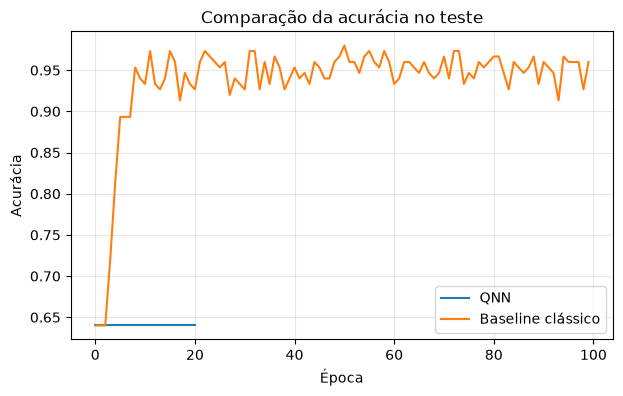

In [52]:
plt.figure(figsize=(7, 4))
plt.plot(history["test_acc"], label="QNN")
plt.plot(classical_history["test_acc"], label="Baseline clássico")
plt.title("Comparação da acurácia no teste")
plt.xlabel("Época")
plt.ylabel("Acurácia")
plt.grid(alpha=0.3)
plt.legend()
plt.show()